# CMIP SST: highest available SSP scenario

Inspect the SST spatial patterns for all models in the same year. Input data are in `/Users/pz/CMIP_AMOC_SST`. Select the highest-forcing SSP **with an available SST file** for each model; the default map shows **annual-mean SST in 2100**.

- Five models provide `ssp585` SST. **GISS-E2-1-G provides only MOC under `ssp585`; its highest available SST scenario is `ssp126`.** Its forcing therefore differs from that of the other five models.
- The files already contain a regular 1° × 1° grid and an annual `year` coordinate. Select one year directly, without interpolation, smoothing, or multi-year averaging. Preserve missing values.
- Convert K to °C using the file's `units` attribute and use a shared color scale. The variable is named `SST`; its metadata describe sea-water potential temperature at scalar `lev = 0`.
- SSP means *Shared Socioeconomic Pathway*. In SSP5-8.5, 8.5 denotes the nominal 2100 radiative-forcing level (W m⁻²), not a CO₂ concentration.
- The SST files contain neither atmospheric CO₂ concentrations nor member identifiers. **The approximately 1135 / 446 ppm labels are standard scenario reference concentrations for 2100, not concentrations read from or verified against these model files.** The reference labels still refer to 2100 if the map year is changed.

Scenario definitions: [DKRZ](https://www.dkrz.de/en/communication/climate-simulations/cmip6-en/the-ssp-scenarios/). Concentrations: [Meinshausen et al. (2020)](https://doi.org/10.5194/gmd-13-3571-2020); rounded values are tabulated in [Jiang et al. (2023), Table 1](https://doi.org/10.1029/2022MS003563).

Plotting code is adapted from cell 6 of `Last_deglaciation/N_minors_S_V3.ipynb` and cell 7 of `Figure_1_Ens.ipynb` (counting all cells from 1). Reused lines and comments include the imports, `ax.set_global()`, grid-label settings, `# Plotting`, `# Using pcolormesh`, `# Add a colorbar`, `# add panel labels`, and `# adjust vertical space between subplots`. Data selection, variable names, layout, and color limits are adapted for SST.

In VS Code, select this project's `.venv/bin/python` and **Run All** from the project root. Dependencies: numpy, pandas, xarray, netCDF4, matplotlib, cartopy, and ipykernel. Coastlines are cached in `data/cartopy/`. Figures are saved as **PNG and PDF** in `figures/SST_highest_SSP/`.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import cartopy
import cartopy.crs as ccrs
from IPython.display import display

project_dir = Path.cwd()
data_dir = Path('/Users/pz/CMIP_AMOC_SST')
figure_dir = project_dir / 'figures' / 'SST_highest_SSP'
figure_dir.mkdir(parents=True, exist_ok=True)
cartopy.config['data_dir'] = project_dir / 'data' / 'cartopy'

plot_year = 2100  # Set to None to use the latest year shared by all models.
vmin, vmax = -2, 38  # SST (°C); one scale for all panels.

# Nominal 2100 forcing, used to rank the SSP scenarios available locally.
ssp_forcing = {'ssp119': 1.9, 'ssp126': 2.6, 'ssp245': 4.5,
               'ssp370': 7.0, 'ssp434': 3.4, 'ssp460': 6.0, 'ssp585': 8.5}
# Rounded global atmospheric CO2 in 2100; scenario references, not file metadata.
co2_2100 = {'ssp126': 446, 'ssp585': 1135}

## Select SSP files

Rank scenarios using SST files that actually exist. A scenario containing only MOC cannot be selected for SST. The table lists scenario directories, available SST scenarios, and the selected scenario.

In [2]:
selected_files = {}
selected_scenarios = {}
selection_rows = []

model_dirs = sorted(path for path in data_dir.iterdir() if path.is_dir())
if not model_dirs:
    raise FileNotFoundError(f'No model directories found in {data_dir}')

for model_dir in model_dirs:
    scenario_dirs = sorted(model_dir.glob('ssp*'))
    sst_files = {}
    for scenario_dir in scenario_dirs:
        files = sorted((scenario_dir / 'SST').glob('*.nc'))
        if files:
            if scenario_dir.name not in ssp_forcing:
                raise ValueError(f'Check SSP forcing before ranking: {scenario_dir.name}')
            if len(files) != 1:
                raise ValueError(f'Check members or time chunks in {scenario_dir / "SST"}')
            sst_files[scenario_dir.name] = files[0]
    if not sst_files:
        raise FileNotFoundError(f'No future SST files for {model_dir.name}')

    scenario = max(sst_files, key=ssp_forcing.get)
    model = model_dir.name
    selected_files[model] = sst_files[scenario]
    selected_scenarios[model] = scenario
    missing_sst = [path.name for path in scenario_dirs if path.name not in sst_files]
    selection_rows.append({
        'model': model,
        'SSP directories': ', '.join(path.name for path in scenario_dirs),
        'available SST': ', '.join(sst_files),
        'selected SSP': scenario,
        '2100 forcing (W m-2)': ssp_forcing[scenario],
        '2100 reference CO2 (ppm)': co2_2100.get(scenario, np.nan),
        'note': f'No SST: {", ".join(missing_sst)}' if missing_sst else '',
    })

selection = pd.DataFrame(selection_rows).set_index('model')
display(selection)

,SSP directories,available SST,selected SSP,2100 forcing (W m-2),2100 reference CO2 (ppm),note
model,,,,,,
ACCESS-CM2,"ssp126, ssp585","ssp126, ssp585",ssp585,8.5,1135,
CESM2,"ssp126, ssp585","ssp126, ssp585",ssp585,8.5,1135,
GISS-E2-1-G,"ssp126, ssp585",ssp126,ssp126,2.6,446,No SST: ssp585
MIROC6,"ssp126, ssp585","ssp126, ssp585",ssp585,8.5,1135,
MPI-ESM1-2-HR,"ssp126, ssp585","ssp126, ssp585",ssp585,8.5,1135,
MRI-ESM2-0,"ssp126, ssp585","ssp126, ssp585",ssp585,8.5,1135,


## Inspect coordinates and select a common year

Read coordinates and metadata before loading a temperature field, then find the intersection of available years. The table reports `units` and `lev` directly from each file.

In [3]:
available_years = {}
metadata_rows = []

for model, path in selected_files.items():
    with xr.open_dataset(path) as ds_sst:
        if set(ds_sst['SST'].dims) != {'year', 'lat', 'lon'}:
            raise ValueError(f'{model}: check SST dimensions {ds_sst.SST.dims}')
        years = ds_sst.year.values
        if not np.all(np.diff(years) > 0):
            raise ValueError(f'{model}: years must be unique and increasing')
        for coord in ['lat', 'lon']:
            if ds_sst[coord].ndim != 1 or not np.all(np.diff(ds_sst[coord]) > 0):
                raise ValueError(f'{model}: check {coord} coordinates')
        available_years[model] = set(years.tolist())
        metadata_rows.append({
            'model': model,
            'first year': int(years.min()),
            'last year': int(years.max()),
            'grid (lat, lon)': (ds_sst.sizes['lat'], ds_sst.sizes['lon']),
            'units': ds_sst.SST.attrs.get('units', ds_sst.attrs.get('units')),
            'lev': float(ds_sst.lev),
            'file': str(path.relative_to(data_dir)),
        })

common_years = sorted(set.intersection(*available_years.values()))
if not common_years:
    raise ValueError('The selected SST files have no common year')
if plot_year is None:
    plot_year = common_years[-1]
if plot_year not in common_years:
    raise ValueError(f'{plot_year} is not shared by all models. Available: {common_years}')

display(pd.DataFrame(metadata_rows).set_index('model'))
print(f'Common years: {common_years[0]}–{common_years[-1]} ({len(common_years)} years)')
print(f'Selected annual-mean SST: {plot_year}')

,first year,last year,"grid (lat, lon)",units,lev,file
model,,,,,,
ACCESS-CM2,2015,2100,"(180, 360)",K,0.0,ACCESS-CM2/ssp585/SST/sst_ACCESS-CM2_ssp585_an...
CESM2,2015,2100,"(180, 360)",K,0.0,CESM2/ssp585/SST/sst_CESM2_ssp585_ann_2015_210...
GISS-E2-1-G,2015,2100,"(180, 360)",K,0.0,GISS-E2-1-G/ssp126/SST/sst_GISS-E2-1-G_ssp126_...
MIROC6,2015,2100,"(180, 360)",K,0.0,MIROC6/ssp585/SST/sst_MIROC6_ssp585_ann_2015_2...
MPI-ESM1-2-HR,2015,2100,"(180, 360)",K,0.0,MPI-ESM1-2-HR/ssp585/SST/sst_MPI-ESM1-2-HR_ssp...
MRI-ESM2-0,2015,2100,"(180, 360)",K,0.0,MRI-ESM2-0/ssp585/SST/sst_MRI-ESM2-0_ssp585_an...


Common years: 2015–2100 (86 years)
Selected annual-mean SST: 2100


## Load SST and convert K to °C

Keep the original values in `sst_raw` and the two-dimensional plotting fields in `sst_celsius`. Load only the selected year and close each NetCDF file afterwards. Check finite grid-cell counts and temperature ranges.

In [4]:
sst_raw = {}
sst_celsius = {}
diagnostic_rows = []

for model, path in selected_files.items():
    with xr.open_dataset(path) as ds_sst:
        sst_raw[model] = ds_sst.SST.sel(year=plot_year).transpose('lat', 'lon').load()
        units = ds_sst.SST.attrs.get('units', ds_sst.attrs.get('units', ''))

    if units.strip().lower() in ['k', 'kelvin']:
        # Convert Kelvin to Celsius; preserve the raw field and missing values.
        sst_celsius[model] = sst_raw[model] - 273.15
    elif units.strip().lower() in ['degc', 'degrees_celsius', 'degree_celsius', '°c']:
        sst_celsius[model] = sst_raw[model].copy()
    else:
        raise ValueError(f'{model}: unrecognized SST units {units!r}')
    sst_celsius[model].attrs = dict(sst_raw[model].attrs, units='degC')

    sst = sst_celsius[model]
    finite = np.isfinite(sst)
    if not bool(finite.any()) or bool(np.isinf(sst).any()):
        raise ValueError(f'{model}: SST is empty or contains infinite values')
    diagnostic_rows.append({
        'model': model,
        'year': plot_year,
        'min (°C)': float(sst.min()),
        'max (°C)': float(sst.max()),
        'valid grid cells': int(finite.sum()),
        'missing (%)': float(sst.isnull().mean() * 100),
        'outside color scale': int(((sst < vmin) | (sst > vmax)).sum()),
    })

diagnostics = pd.DataFrame(diagnostic_rows).set_index('model')
display(diagnostics.round(2))

,year,min (°C),max (°C),valid grid cells,missing (%),outside color scale
model,,,,,,
ACCESS-CM2,2100,-1.72,36.99,40895,36.89,0
CESM2,2100,-1.61,35.20,41020,36.70,0
GISS-E2-1-G,2100,-1.91,33.60,40323,37.77,0
MIROC6,2100,-1.66,35.56,40068,38.17,0
MPI-ESM1-2-HR,2100,-1.47,33.55,41315,36.24,0
MRI-ESM2-0,2100,-1.66,33.73,42951,33.72,0


## Plot SST

Use the Robinson global projection and the actual longitude and latitude coordinates. Grey represents land or missing data in the input file; no values are filled. Each panel shows the model, selected SSP, and **2100 reference CO₂ concentration**. The missing `ssp585` SST file for GISS is explicitly marked. Export the same figure to PNG and PDF; the PDF retains vector text and coastlines with a rasterized SST mesh.

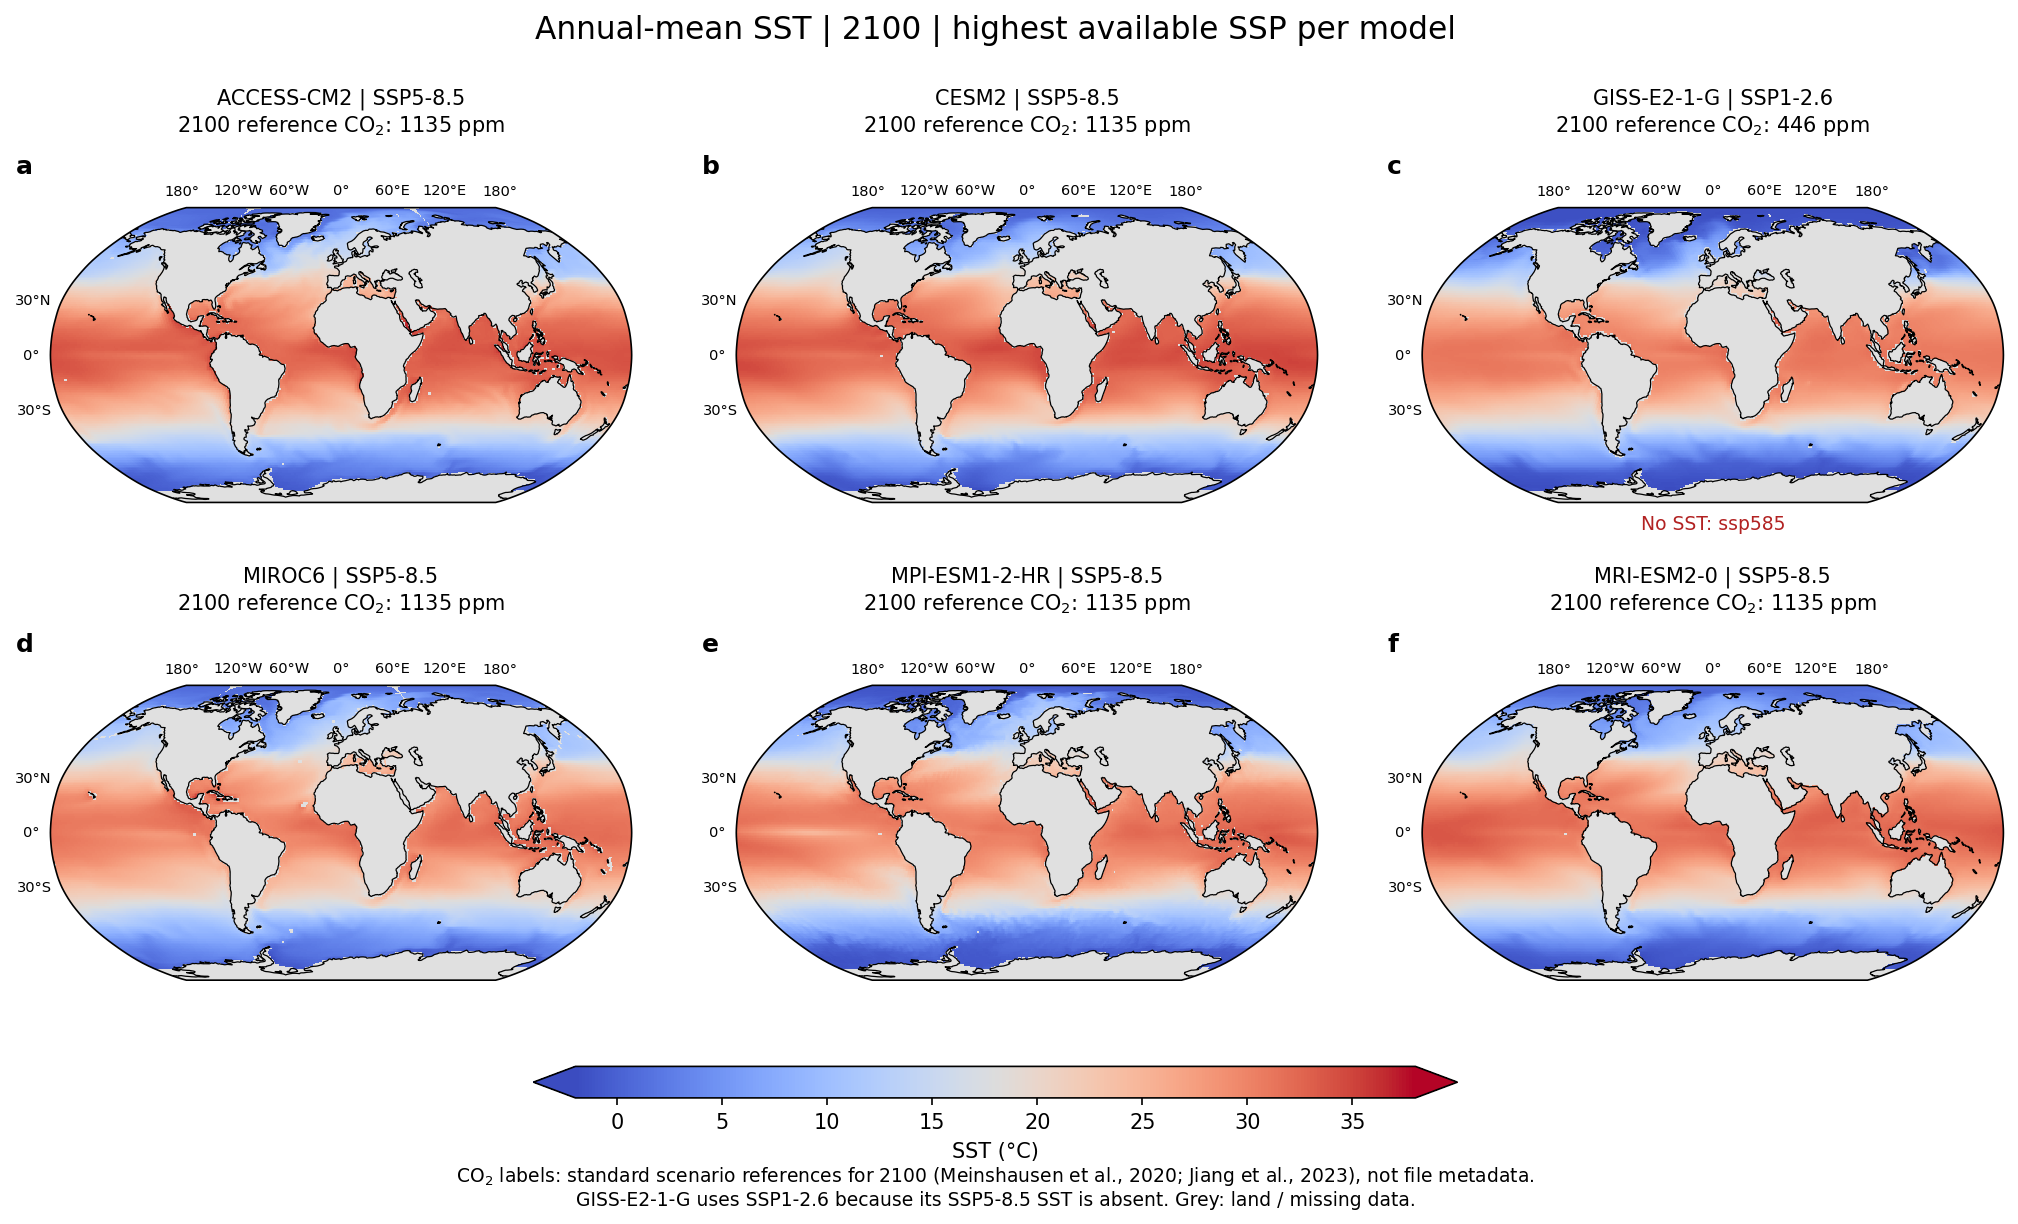

/Users/pz/VScode/MOC_ana/figures/SST_highest_SSP/SST_highest_SSP_2100.png
/Users/pz/VScode/MOC_ana/figures/SST_highest_SSP/SST_highest_SSP_2100.pdf


In [5]:
# Plotting
ncols = 3
nrows = int(np.ceil(len(sst_celsius) / ncols))
fig, axs = plt.subplots(nrows=nrows, ncols=ncols, figsize=(14, 4.2 * nrows),
                        subplot_kw={'projection': ccrs.Robinson()}, dpi=150,
                        squeeze=False)

for i, (model, sst) in enumerate(sst_celsius.items()):
    ax = axs.flat[i]
    scenario = selected_scenarios[model]
    ax.set_global()
    ax.set_facecolor('0.88')

    # Using pcolormesh
    map_plot = ax.pcolormesh(sst['lon'], sst['lat'], sst,
                            cmap='coolwarm', vmin=vmin, vmax=vmax,
                            transform=ccrs.PlateCarree(), shading='auto',
                            rasterized=True)
    ax.coastlines(resolution='110m', linewidth=0.6)
    gl = ax.gridlines(draw_labels=False)
    gl.xlines = False
    gl.ylines = False
    gl.top_labels = True
    gl.bottom_labels = False
    gl.left_labels = True
    gl.right_labels = False
    gl.xlabel_style = {'size': 7}
    gl.ylabel_style = {'size': 7}

    ssp_label = f'SSP{scenario[3]}-{ssp_forcing[scenario]:.1f}'
    co2_label = (f'{co2_2100[scenario]:.0f} ppm' if scenario in co2_2100 else 'not supplied')
    ax.set_title(f'{model} | {ssp_label}\n2100 reference CO$_2$: {co2_label}',
                 fontsize=10, pad=25)
    if selection.loc[model, 'note']:
        ax.text(0.5, -0.09, selection.loc[model, 'note'], transform=ax.transAxes,
                fontsize=9, ha='center', color='firebrick')

    # add panel labels
    ax.text(-0.06, 1.18, chr(97 + i), transform=ax.transAxes,
            fontsize=12, fontweight='bold', va='top')

for ax in axs.flat[len(sst_celsius):]:
    ax.set_visible(False)

# adjust vertical space between subplots
plt.subplots_adjust(hspace=0.35)
fig.subplots_adjust(left=0.05, right=0.98, top=0.85, bottom=0.19, wspace=0.18)

# Add a colorbar
cbar_ax = fig.add_axes([0.28, 0.12, 0.44, 0.025])
cbar = fig.colorbar(map_plot, cax=cbar_ax, orientation='horizontal', extend='both')
cbar.set_label('SST (°C)')
cbar.set_ticks([0, 5, 10, 15, 20, 25, 30, 35])

fig.suptitle(f'Annual-mean SST | {plot_year} | highest available SSP per model',
             fontsize=15, y=0.98)
fig.text(0.5, 0.035,
         'CO$_2$ labels: standard scenario references for 2100 (Meinshausen et al., 2020; Jiang et al., 2023), not file metadata.\n'
         'GISS-E2-1-G uses SSP1-2.6 because its SSP5-8.5 SST is absent. Grey: land / missing data.',
         ha='center', fontsize=9)

figure_path = figure_dir / f'SST_highest_SSP_{plot_year}.png'
fig.savefig(figure_path, dpi=300, bbox_inches='tight')
fig.savefig(figure_path.with_suffix('.pdf'), dpi=300, bbox_inches='tight')
plt.show()
print(figure_path)
print(figure_path.with_suffix('.pdf'))